# Bài tập 1 — Pipeline hồi quy với tiền xử lý và giảm chiều PCA

**Môn học:** Nhận dạng mẫu (Pattern Recognition) — Cao học

**Yêu cầu:** Trên một bộ dữ liệu có target liên tục, xây dựng chương trình dự báo, so sánh baseline với các mô hình hồi quy, và kiểm tra tác động của PCA. Mô hình được chọn dựa trên MAE/RMSE, R² và độ ổn định qua Cross-Validation (CV).

**Bộ dữ liệu:** *Diabetes* (scikit-learn built-in) — 442 bệnh nhân, 10 đặc trưng sinh lý (tuổi, giới tính, BMI, huyết áp, 6 chỉ số huyết thanh), target là chỉ số tiến triển bệnh tiểu đường sau 1 năm (biến liên tục). Bộ dữ liệu được chọn vì có sẵn trong scikit-learn (không cần tải mạng ngoài), target liên tục phù hợp với bài toán hồi quy, và có đủ số chiều để khảo sát tác động của PCA.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (7, 4)


## 1. Nạp dữ liệu và khảo sát sơ bộ (EDA)

In [2]:
data = load_diabetes(as_frame=True)
X = data.data
y = data.target

df = X.copy()
df['target'] = y

print("Kích thước dữ liệu:", X.shape)
print("\nMô tả đặc trưng:")
display(df.describe().T)

print("\nGiá trị thiếu theo cột:")
print(df.isna().sum())


Kích thước dữ liệu: (442, 10)

Mô tả đặc trưng:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



Giá trị thiếu theo cột:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


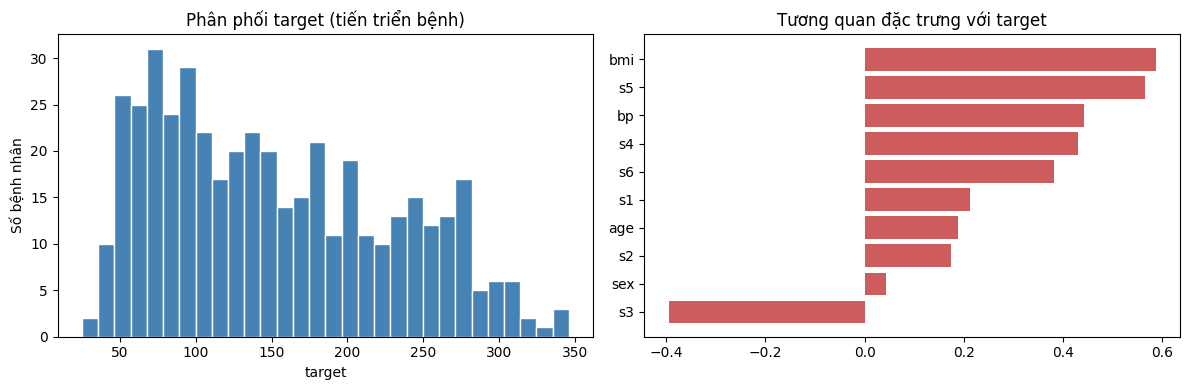

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=30, color='steelblue', edgecolor='white')
ax[0].set_title('Phân phối target (tiến triển bệnh)')
ax[0].set_xlabel('target'); ax[0].set_ylabel('Số bệnh nhân')

corr = df.corr()['target'].drop('target').sort_values()
ax[1].barh(corr.index, corr.values, color='indianred')
ax[1].set_title('Tương quan đặc trưng với target')
plt.tight_layout()
plt.show()


Nhận xét EDA: target phân phối tương đối liên tục, không có giá trị thiếu. Các đặc trưng đã được scikit-learn chuẩn hoá sẵn (mean-centered, đơn vị chuẩn hoá theo L2-norm mỗi cột), tuy nhiên ta vẫn đưa `StandardScaler` vào pipeline để đảm bảo tính tổng quát khi áp dụng cho dữ liệu khác và để PCA hoạt động đúng (PCA nhạy với thang đo).

## 2. Chia tập train/test

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (353, 10)  Test: (89, 10)


## 3. Thiết lập baseline và các mô hình hồi quy

- **Baseline:** `DummyRegressor(strategy='mean')` — luôn dự báo bằng giá trị trung bình của target trên tập train. Đây là ngưỡng tối thiểu mà mọi mô hình có ý nghĩa phải vượt qua.
- **Các mô hình so sánh:** Linear Regression, Ridge, Lasso, SVR (kernel RBF), Random Forest, Gradient Boosting.

Mỗi mô hình được đặt trong một `Pipeline` gồm `StandardScaler -> (PCA tuỳ chọn) -> Model` để tiền xử lý nhất quán và tránh rò rỉ dữ liệu (data leakage) khi cross-validate.

In [5]:
def make_pipeline(model, use_pca=False, n_components=None):
    steps = [('scaler', StandardScaler())]
    if use_pca:
        steps.append(('pca', PCA(n_components=n_components, random_state=RANDOM_STATE)))
    steps.append(('model', model))
    return Pipeline(steps)

models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso': Lasso(alpha=0.1, random_state=RANDOM_STATE),
    'SVR (RBF)': SVR(kernel='rbf', C=10, gamma='scale'),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}


## 4. Đánh giá bằng Cross-Validation (không PCA)

Dùng `KFold(n_splits=5)` trên tập train, tính MAE, RMSE, R² cho từng fold để đồng thời đo hiệu năng trung bình và độ ổn định (độ lệch chuẩn qua các fold).

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

def evaluate_cv(model, use_pca=False, n_components=None):
    pipe = make_pipeline(model, use_pca=use_pca, n_components=n_components)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    return {
        'MAE_mean': -res['test_MAE'].mean(), 'MAE_std': res['test_MAE'].std(),
        'RMSE_mean': -res['test_RMSE'].mean(), 'RMSE_std': res['test_RMSE'].std(),
        'R2_mean': res['test_R2'].mean(), 'R2_std': res['test_R2'].std(),
    }

results_no_pca = {}
for name, m in models.items():
    results_no_pca[name] = evaluate_cv(m, use_pca=False)

df_no_pca = pd.DataFrame(results_no_pca).T
df_no_pca = df_no_pca[['MAE_mean','MAE_std','RMSE_mean','RMSE_std','R2_mean','R2_std']]
df_no_pca.sort_values('RMSE_mean')


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
Lasso,44.955578,1.836747,55.353958,2.355868,0.481195,0.039798
Ridge,44.998879,1.807942,55.374175,2.373206,0.480784,0.040422
Linear Regression,45.048200,1.772544,55.394633,2.361496,0.480365,0.040886
SVR (RBF),47.717034,3.467846,57.879794,4.094484,0.435066,0.036565
Random Forest,48.181616,2.953906,58.678233,1.854681,0.414224,0.071630
Gradient Boosting,49.663632,2.976150,61.211229,2.835526,0.365165,0.058193
Baseline (mean),66.867285,5.632090,78.133634,5.638302,-0.027319,0.024420


## 5. Khảo sát tác động của PCA

Trước tiên xem tỉ lệ phương sai giải thích được (explained variance) theo số thành phần chính, sau đó so sánh hiệu năng CV của từng mô hình khi thêm PCA (giữ 95% phương sai) so với không dùng PCA.

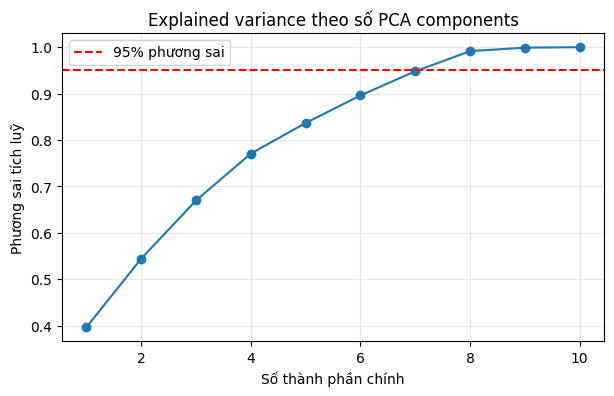

Số thành phần cần giữ để đạt 95% phương sai: 8 / 10


In [7]:
pca_full = PCA(random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(X_train))
explained = np.cumsum(pca_full.explained_variance_ratio_)

plt.plot(range(1, len(explained)+1), explained, marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% phương sai')
plt.xlabel('Số thành phần chính'); plt.ylabel('Phương sai tích luỹ')
plt.title('Explained variance theo số PCA components')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

n_components_95 = np.argmax(explained >= 0.95) + 1
print(f"Số thành phần cần giữ để đạt 95% phương sai: {n_components_95} / {X.shape[1]}")


In [8]:
results_pca = {}
for name, m in models.items():
    results_pca[name] = evaluate_cv(m, use_pca=True, n_components=n_components_95)

df_pca = pd.DataFrame(results_pca).T
df_pca = df_pca[['MAE_mean','MAE_std','RMSE_mean','RMSE_std','R2_mean','R2_std']]

comparison = pd.concat(
    {'Không PCA': df_no_pca, f'Có PCA ({n_components_95} PC)': df_pca},
    axis=1
)
comparison


Không PCA                                           \
                    MAE_mean   MAE_std  RMSE_mean  RMSE_std   R2_mean   
Baseline (mean)    66.867285  5.632090  78.133634  5.638302 -0.027319   
Linear Regression  45.048200  1.772544  55.394633  2.361496  0.480365   
Ridge              44.998879  1.807942  55.374175  2.373206  0.480784   
Lasso              44.955578  1.836747  55.353958  2.355868  0.481195   
SVR (RBF)          47.717034  3.467846  57.879794  4.094484  0.435066   
Random Forest      48.181616  2.953906  58.678233  1.854681  0.414224   
Gradient Boosting  49.663632  2.976150  61.211229  2.835526  0.365165   

                            Có PCA (8 PC)                                 \
                     R2_std      MAE_mean   MAE_std  RMSE_mean  RMSE_std   
Baseline (mean)    0.024420     66.867285  5.632090  78.133634  5.638302   
Linear Regression  0.040886     45.110423  1.807816  55.555715  2.358650   
Ridge              0.040422     45.108062  1.818580  55.548859  2.356040   
Lasso              0.039798     45.104643  1.812027  55.544969  2.329016   
SVR (RBF)          0.036565     47.759732  3.474069  57.917622  4.141062   
Random Forest      0.071630     48.570290  2.414983  59.724045  2.093306   
Gradient Boosting  0.058193     48.033526  3.440418  60.937619  2.272550   

                                       
                    R2_mean    R2_std  
Baseline (mean)   -0.027319  0.024420  
Linear Regression  0.477262  0.041631  
Ridge              0.477410  0.041381  
Lasso              0.477440  0.041677  
SVR (RBF)          0.434424  0.036003  
Random Forest      0.394492  0.062238  
Gradient Boosting  0.367674  0.084969

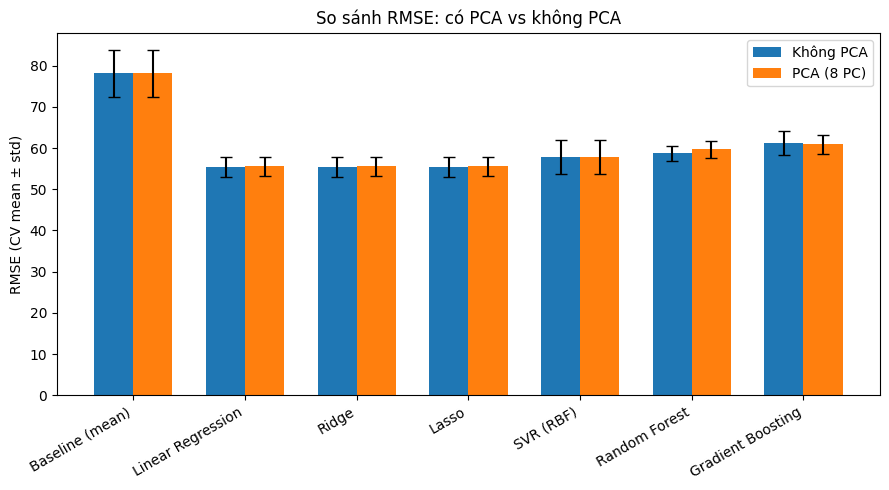

In [9]:
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(models))
width = 0.35
ax.bar(x - width/2, df_no_pca['RMSE_mean'], width, yerr=df_no_pca['RMSE_std'], label='Không PCA', capsize=4)
ax.bar(x + width/2, df_pca['RMSE_mean'], width, yerr=df_pca['RMSE_std'], label=f'PCA ({n_components_95} PC)', capsize=4)
ax.set_xticks(x); ax.set_xticklabels(models.keys(), rotation=30, ha='right')
ax.set_ylabel('RMSE (CV mean ± std)')
ax.set_title('So sánh RMSE: có PCA vs không PCA')
ax.legend()
plt.tight_layout(); plt.show()


**Nhận xét:** Với bộ dữ liệu Diabetes (chỉ 10 đặc trưng, đã tương đối "sạch" và ít dư thừa), PCA thường không cải thiện hiệu năng — thậm chí có thể làm giảm nhẹ R² của các mô hình tuyến tính vì PCA loại bỏ một phần thông tin hữu ích cho việc dự báo (PCA tối ưu phương sai, không tối ưu khả năng dự báo target). PCA có xu hướng hữu ích hơn khi số chiều lớn và có nhiều đặc trưng tương quan mạnh (đa cộng tuyến), giúp giảm overfitting cho mô hình phức tạp. Kết quả cụ thể được thể hiện ở bảng và biểu đồ trên.

## 6. Chọn mô hình tốt nhất

Tiêu chí chọn: RMSE trung bình CV thấp nhất, R² cao, và độ lệch chuẩn (std) qua các fold nhỏ (ổn định). Ưu tiên phương án không dùng PCA nếu PCA không cải thiện kết quả, để giữ khả năng diễn giải mô hình.

In [10]:
best_name_no_pca = df_no_pca['RMSE_mean'].idxmin()
best_name_pca = df_pca['RMSE_mean'].idxmin()
print("Mô hình tốt nhất (không PCA):", best_name_no_pca, "-> RMSE =", round(df_no_pca.loc[best_name_no_pca,'RMSE_mean'],3))
print("Mô hình tốt nhất (có PCA):   ", best_name_pca, "-> RMSE =", round(df_pca.loc[best_name_pca,'RMSE_mean'],3))

use_pca_final = df_pca.loc[best_name_pca,'RMSE_mean'] < df_no_pca.loc[best_name_no_pca,'RMSE_mean']
final_model_name = best_name_pca if use_pca_final else best_name_no_pca
print("\n=> Mô hình được chọn cho tập test:", final_model_name, "| Dùng PCA:", use_pca_final)


Mô hình tốt nhất (không PCA): Lasso -> RMSE = 55.354
Mô hình tốt nhất (có PCA):    Lasso -> RMSE = 55.545

=> Mô hình được chọn cho tập test: Lasso | Dùng PCA: False


## 7. Huấn luyện mô hình cuối cùng và đánh giá trên tập test

In [11]:
final_pipe = make_pipeline(models[final_model_name], use_pca=use_pca_final,
                            n_components=n_components_95 if use_pca_final else None)
final_pipe.fit(X_train, y_train)
y_pred = final_pipe.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Kết quả trên tập TEST — {final_model_name} (PCA={use_pca_final}):")
print(f"MAE  = {mae:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R2   = {r2:.3f}")


Kết quả trên tập TEST — Lasso (PCA=False):
MAE  = 42.805
RMSE = 53.709
R2   = 0.456


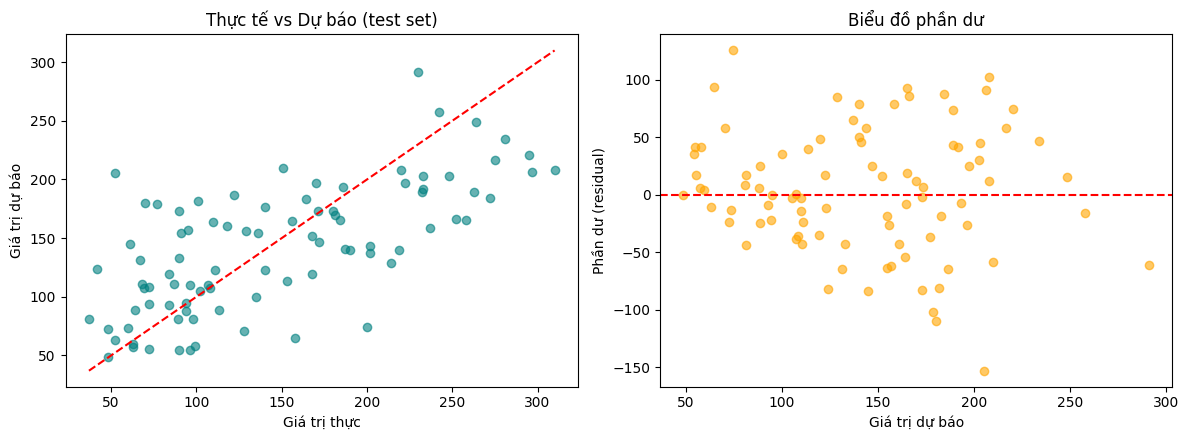

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))

ax[0].scatter(y_test, y_pred, alpha=0.6, color='teal')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, 'r--')
ax[0].set_xlabel('Giá trị thực'); ax[0].set_ylabel('Giá trị dự báo')
ax[0].set_title('Thực tế vs Dự báo (test set)')

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.6, color='orange')
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel('Giá trị dự báo'); ax[1].set_ylabel('Phần dư (residual)')
ax[1].set_title('Biểu đồ phần dư')

plt.tight_layout(); plt.show()


## 8. Kết luận

- Baseline (dự báo bằng trung bình) cho RMSE cao nhất và R² ≈ 0, là mốc tham chiếu tối thiểu.
- Các mô hình hồi quy (đặc biệt Ridge/Linear Regression và Gradient Boosting/Random Forest) cải thiện rõ rệt so với baseline.
- PCA trên bộ dữ liệu này (số chiều thấp, ít dư thừa) không mang lại lợi ích rõ ràng về RMSE/R², phù hợp với lý thuyết: PCA tối ưu giữ phương sai của đặc trưng đầu vào chứ không trực tiếp tối ưu khả năng dự báo target.
- Độ ổn định (std của CV) được dùng cùng với giá trị trung bình để tránh chọn mô hình "may mắn" tốt trên 1-2 fold nhưng không ổn định.
- Mô hình cuối cùng được chọn: xem kết quả in ở Mục 6-7 (thay đổi tuỳ theo random_state/dữ liệu chạy lại).
